# Coupled spin-ups after the CO₂ fix: are they in equilibrium at year 20?

**Runs (CO₂-fix chain, 20 yr each, fixed SST/sea ice, `NF2000…` / `NF2100ssp585…`).** Each starts from its own 100-yr land-only spin-up, so CTRL and LCC now have the same spin-up history (the old chain gave the land-only spin-up only to LCC).

| Label | Script | Case | Land initial state |
|---|---|---|---|
| `CTRL_PD_spinup` | 13c | `NF2000norbc_tropstratchem_spinup_ctrl_f19_f19-20261026` | CTRL_PD land-only `-20261025` |
| `LCC_PD_spinup` | 13b | `NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20261025` | LCC_PD land-only `-20261023` |
| `CTRL_FUT_spinup` | 23c | `NF2100ssp585norbc_tropstratchem_spinup_ctrl_f19_f19-20261025` | CTRL_FUT land-only `-20261023` |
| `LCC_FUT_spinup` | 23b | `NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20261025` | LCC_FUT land-only `-20261023` |

Reference (old chain, dashed): `PD_spinup` (11) / `FUT_spinup` (21, `-3`) = old CTRL, and `LCC_PD_spinup_old` / `LCC_FUT_spinup_old` (`-20260928`, from the old land-only spin-ups; FUT with the CO₂ bug).

**The nudged runs start from year 21 (restart `0021-01-01`).** So the questions are:
1. **Drift (per run):** is the state at the end flat compared with its year-to-year noise?
2. **Members (per period):** outside the modified cells, does LCC − CTRL stay small now? In the old chain it did not (e.g. PD tropics TOTVEGC +10 %), because the spin-up histories differed.

**Tests.** IAV = SD of the detrended last 10 annual values. The SSTs are a fixed climatology, so there is no forcing cycle and an OLS trend is meaningful (unlike the land-only runs, which loop 10 forcing years).
- `ratio_ols` = |OLS trend over the last 10 yr, per decade| / IAV.
- `ratio_block` = |mean(last 5 yr) − mean(previous 5 yr)| / IAV.
- Below 1, the drift over a decade (or between two 5-yr blocks) is smaller than one year of noise. Descriptive, not a hard threshold (no autocorrelation correction).
- Members: Δ = LCC − CTRL over the last 10 common years, in units of CTRL's IAV and in %. In a coupled run the atmosphere carries part of the land-cover signal to unmodified cells, so Δ there need not be exactly 0. A spin-up mismatch shows up as a large Δ in the **slow pools** (TOTVEGC, TOTSOMC, TOTECOSYSC); compare with the old pairs.

Regions: modified cells; unmodified land; global land. CLM and CAM land regions weighted by `area × landfrac`; CAM also `global` (cos lat, all cells). Annual means weighted by the length of each time-bounds interval; only complete years (365 days) are kept.

**`CTRL_PD_spinup` is still running** (last segment, ends ~29 Oct 05:00). The notebook uses the complete years available; rerun it with `REBUILD_CACHE = True` for that run when it is finished.

In [1]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import
from pathlib import Path
import re
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import netCDF4
from IPython.display import display

# Betzy work archive first (complete, also for running cases), NIRD archive as fallback.
ARCHIVES = [Path('/cluster/work/users/adelez/archive'), Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')]
MASK_FILE = Path('../../lcc-modified-cells/modified_cells.nc')
OUT = Path('check_coupled_spinup_equilibrium_after_co2_fix_outputs')
CACHE = OUT / 'cache'  # regenerable annual means; delete or set REBUILD_CACHE after changing inputs
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = {'CTRL_PD_spinup'}  # runs whose cache is rebuilt (CTRL_PD_spinup is still running); set() = none

RUNS = pd.DataFrame([
    ('CTRL_PD_spinup',     'PD',  'CTRL', 'new', 'NF2000norbc_tropstratchem_spinup_ctrl_f19_f19-20261026'),
    ('LCC_PD_spinup',      'PD',  'LCC',  'new', 'NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20261025'),
    ('CTRL_FUT_spinup',    'FUT', 'CTRL', 'new', 'NF2100ssp585norbc_tropstratchem_spinup_ctrl_f19_f19-20261025'),
    ('LCC_FUT_spinup',     'FUT', 'LCC',  'new', 'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20261025'),
    ('PD_spinup',          'PD',  'CTRL', 'old', 'NF2000norbc_tropstratchem_spinup_f19_f19'),
    ('LCC_PD_spinup_old',  'PD',  'LCC',  'old', 'NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20260928'),
    ('FUT_spinup',         'FUT', 'CTRL', 'old', 'NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3'),
    ('LCC_FUT_spinup_old', 'FUT', 'LCC',  'old', 'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20260928'),
], columns=['run', 'period', 'branch', 'version', 'case']).set_index('run')
NEW = list(RUNS.index[RUNS.version == 'new'])
PAIRS = {'PD new': ('CTRL_PD_spinup', 'LCC_PD_spinup'), 'FUT new': ('CTRL_FUT_spinup', 'LCC_FUT_spinup'),
         'PD old': ('PD_spinup', 'LCC_PD_spinup_old'), 'FUT old': ('FUT_spinup', 'LCC_FUT_spinup_old')}

LND_VARS = ['TLAI', 'HTOP', 'TWS', 'H2OSOI_1m', 'TSOI_1m', 'GPP', 'TOTVEGC', 'TOTVEGN', 'TOTSOMC', 'TOTECOSYSC']
SOIL = {'H2OSOI_1m': 'H2OSOI', 'TSOI_1m': 'TSOI'}
SOIL_INDEX = 8  # levgrnd[8] = 1.06 m (asserted)
ATM_VARS = ['TREFHT', 'TS', 'FSNT', 'FLNT', 'CLDTOT']  # RESTOM = FSNT - FLNT is derived
SHORT_TERM = ['TWS', 'H2OSOI_1m', 'TSOI_1m', 'TLAI']
SLOW = ['TOTVEGC', 'TOTSOMC', 'TOTECOSYSC', 'TOTVEGN', 'HTOP', 'GPP']
ATM = ['TREFHT', 'RESTOM', 'CLDTOT']
LAST, BLOCK = 10, 5
COLOR = {'CTRL_PD_spinup': '#2C3990', 'LCC_PD_spinup': '#BC423E', 'CTRL_FUT_spinup': '#2C3990', 'LCC_FUT_spinup': '#BC423E',
         'PD_spinup': '#2C3990', 'LCC_PD_spinup_old': '#BC423E', 'FUT_spinup': '#2C3990', 'LCC_FUT_spinup_old': '#BC423E'}

## 1. Read the annual means

One cache file per run and component in `check_coupled_spinup_equilibrium_after_co2_fix_outputs/cache/`. Reads every record of every h0 file (works for one-month and multi-month files) and weights each by its time-bounds length.

In [2]:
def hist_files(case, comp):
    sub, pat = {'lnd': ('lnd/hist', '*.clm2.h0.*.nc'), 'atm': ('atm/hist', '*.cam.h0.*.nc')}[comp]
    for root in ARCHIVES:
        files = sorted((root / case / sub).glob(pat))
        if files:
            return files
    raise FileNotFoundError(f'{case} {comp}')

def read_file(path, comp):
    with netCDF4.Dataset(path) as d:
        t = d['time']
        assert t.calendar in ('noleap', '365_day') and re.fullmatch(r'days since \d{4}-01-01( 00:00:00)?', t.units), (path, t.units)
        bname = getattr(t, 'bounds', None) or next(b for b in ('time_bounds', 'time_bnds') if b in d.variables)
        bounds = d[bname][:].astype(float)
        mid = bounds.mean(1)
        out = dict(mid=mid, year=int(t.units.split()[2][:4]) + np.floor(mid / 365).astype(int), days=bounds[:, 1] - bounds[:, 0])
        for v in (LND_VARS if comp == 'lnd' else ATM_VARS):
            if v in d.variables:
                out[v] = np.ma.filled(d[v][:].astype(float), np.nan)
        if comp == 'lnd':
            for new, old in SOIL.items():
                if old in d.variables:
                    assert abs(float(d['levgrnd'][SOIL_INDEX]) - 1.06) < 0.01, f'{path}: soil levels changed'
                    out[new] = np.ma.filled(d[old][:, SOIL_INDEX].astype(float), np.nan)
        elif 'FSNT' in out and 'FLNT' in out:
            out['RESTOM'] = out['FSNT'] - out['FLNT']
    return out

def annual_means(case, comp):
    files = hist_files(case, comp)
    parts = [read_file(f, comp) for f in files]
    mid = np.concatenate([p['mid'] for p in parts])
    assert len(np.unique(mid)) == len(mid), f'{case}: duplicated time steps'
    year = np.concatenate([p['year'] for p in parts])
    days = np.concatenate([p['days'] for p in parts])
    keep = [y for y in np.unique(year) if abs(days[year == y].sum() - 365) < 0.5]
    names = [v for v in parts[0] if v not in ('mid', 'year', 'days') and all(v in p for p in parts)]
    with netCDF4.Dataset(files[0]) as d:
        coords = dict(lat=d['lat'][:].data, lon=d['lon'][:].data)
        grid = {v: (('lat', 'lon'), np.ma.filled(d[v][:].astype(float), np.nan)) for v in ('area', 'landfrac') if v in d.variables}
        units = {v: getattr(d[SOIL.get(v, v)], 'units', '?') for v in names if SOIL.get(v, v) in d.variables}
    units['RESTOM'] = 'W/m2'
    data = {}
    for v in names:
        x = np.concatenate([p[v] for p in parts])
        rows = []
        for y in keep:
            sel = year == y
            total = np.nansum(x[sel] * days[sel][:, None, None], 0)
            total[np.isnan(x[sel]).all(0)] = np.nan
            rows.append(total / days[sel].sum())
        data[v] = (('year', 'lat', 'lon'), np.stack(rows), {'units': units.get(v, '?')})
    return xr.Dataset({**data, **grid}, coords=dict(year=keep, **coords), attrs=dict(case=case, source=str(files[0].parent)))

def load(run, comp):
    f = CACHE / f'annual_{comp}_{run}.nc'
    if run in REBUILD_CACHE or not f.exists():
        annual_means(RUNS.case[run], comp).to_netcdf(f)
    return xr.open_dataset(f).load()

ANN = {(run, comp): load(run, comp) for run in RUNS.index for comp in ('lnd', 'atm')}
display(pd.DataFrame({run: {f'{comp} years': f"{int(ANN[run, comp].year[0])}–{int(ANN[run, comp].year[-1])} ({ANN[run, comp].sizes['year']})"
                            for comp in ('lnd', 'atm')} for run in RUNS.index}).T)

,lnd years,atm years
CTRL_PD_spinup,1–15 (15),1–15 (15)
LCC_PD_spinup,1–20 (20),1–20 (20)
CTRL_FUT_spinup,1–20 (20),1–20 (20)
LCC_FUT_spinup,1–20 (20),1–20 (20)
PD_spinup,1–20 (20),1–20 (20)
LCC_PD_spinup_old,1–20 (20),1–20 (20)
FUT_spinup,1–20 (20),1–20 (20)
LCC_FUT_spinup_old,1–20 (20),1–20 (20)


In [3]:
ref = ANN['LCC_PD_spinup', 'lnd']
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon)
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
REGIONS = {'modified cells': LAND & mask, 'unmodified land': LAND & ~mask, 'global land': LAND}
W_LAND = ref.area * ref.landfrac
COSLAT = np.cos(np.deg2rad(ref.lat)) * xr.ones_like(ref.lon)

def regional_mean(field, region):
    if region == 'global':
        w = COSLAT.where(np.isfinite(field))
    else:
        w = W_LAND.assign_coords(lat=field.lat, lon=field.lon).where(REGIONS[region].values & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

def comp_of(v):
    return 'lnd' if v in LND_VARS else 'atm'

def per_year(v, field):
    return field * 86400 * 365 if v == 'GPP' else field

def units_of(v):
    return 'gC/m^2/yr' if v == 'GPP' else next(ANN[r, comp_of(v)][v].attrs['units'] for r in RUNS.index if v in ANN[r, comp_of(v)])

def regions_of(v):
    return list(REGIONS) + (['global'] if comp_of(v) == 'atm' else [])

for run in RUNS.index:  # same grid in every run and component (never remap silently)
    for comp in ('lnd', 'atm'):
        assert np.allclose(ANN[run, comp].lat, ref.lat, atol=1e-5) and np.allclose(ANN[run, comp].lon, ref.lon, atol=1e-5), (run, comp)

SERIES = {(run, r, v): regional_mean(per_year(v, ANN[run, comp_of(v)][v]), r)
          for run in RUNS.index for v in SHORT_TERM + SLOW + ATM if v in ANN[run, comp_of(v)] for r in regions_of(v)}
missing = sorted({(run, v) for run in RUNS.index for v in SHORT_TERM + SLOW + ATM if v not in ANN[run, comp_of(v)]})
print('Not in the output (skipped):', missing or 'none')

Not in the output (skipped): [('LCC_FUT_spinup_old', 'HTOP'), ('LCC_FUT_spinup_old', 'TOTVEGN'), ('LCC_FUT_spinup_old', 'TWS'), ('LCC_PD_spinup_old', 'HTOP'), ('LCC_PD_spinup_old', 'TOTVEGN'), ('LCC_PD_spinup_old', 'TWS')]


## 2. Time series

Thin: annual means; thick: 5-yr running mean. Solid: new chain; dashed: old chain. Blue CTRL, orange LCC. PD left block, FUT right block.

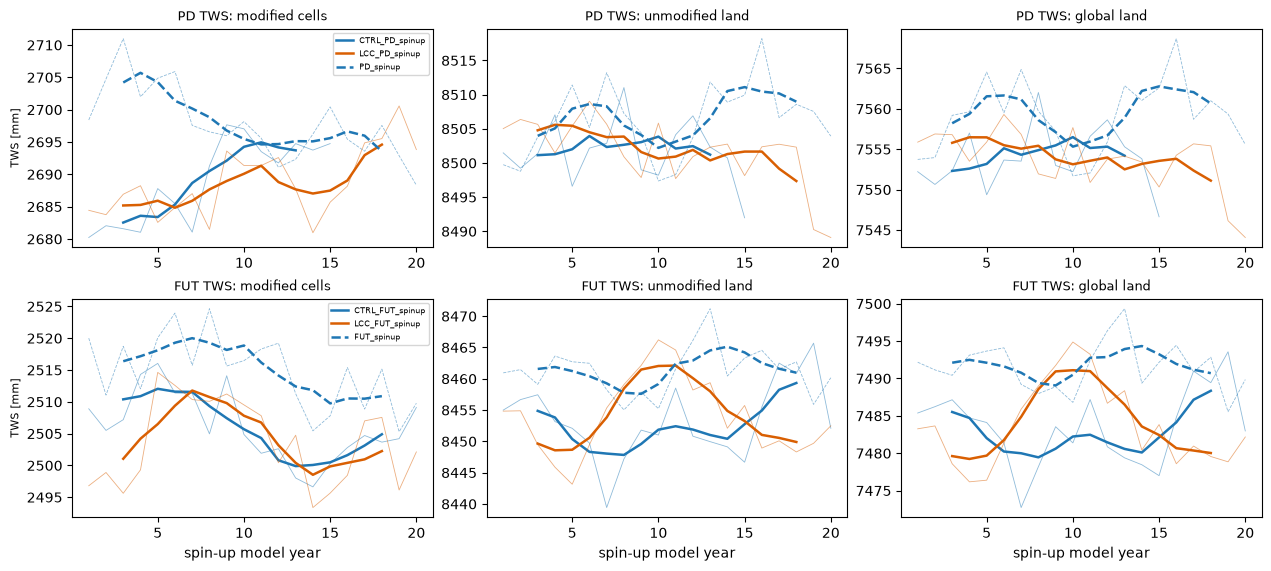

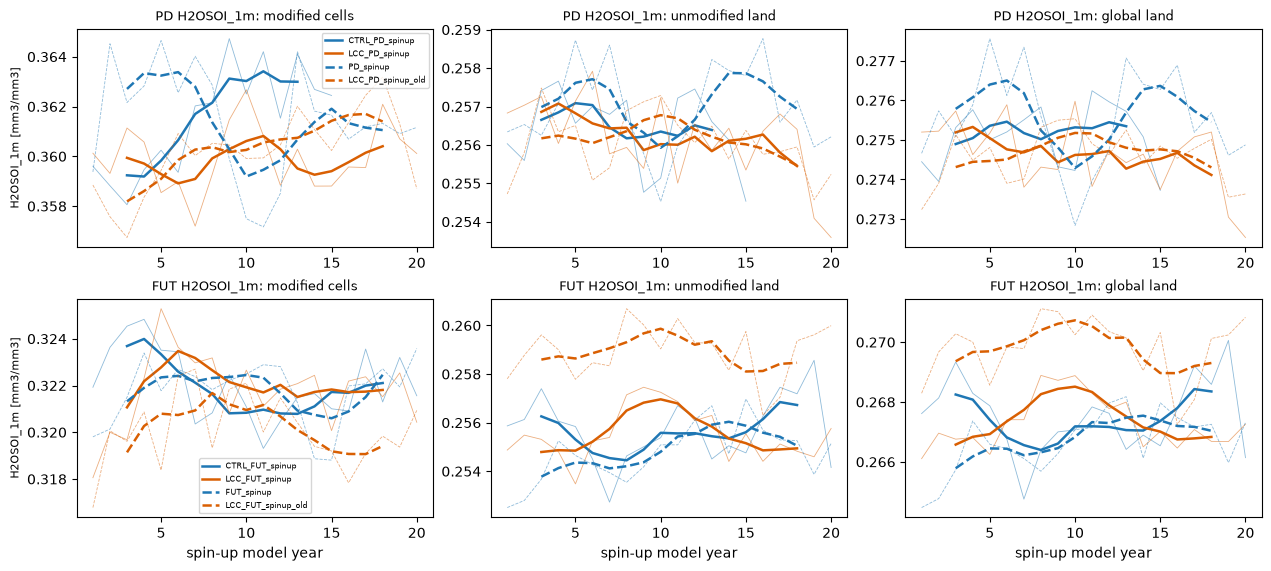

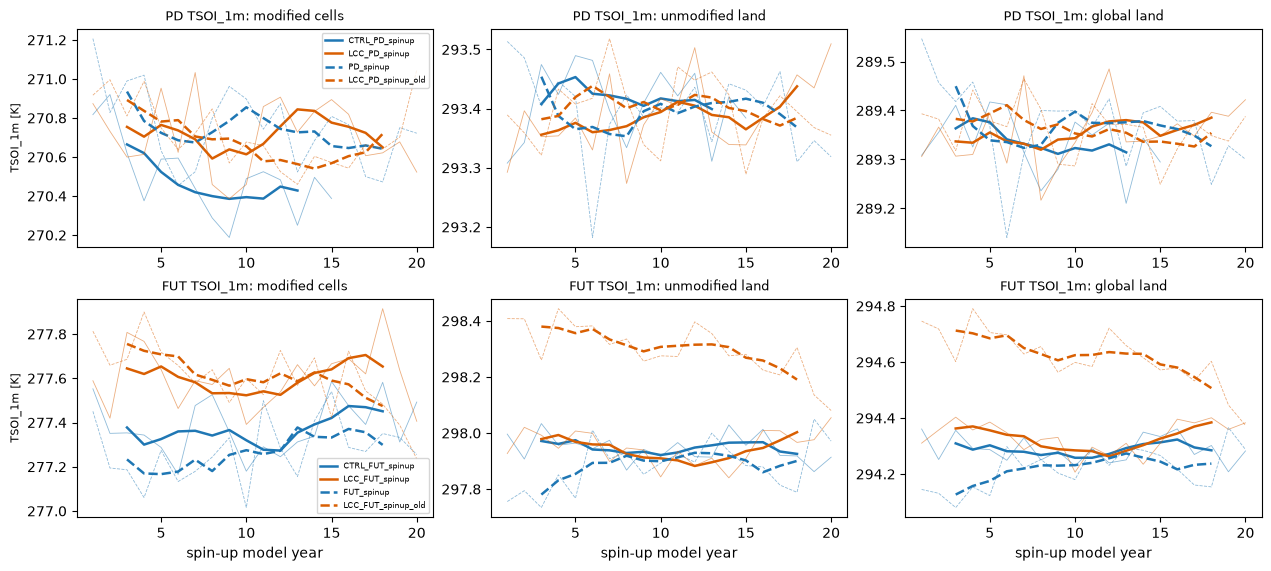

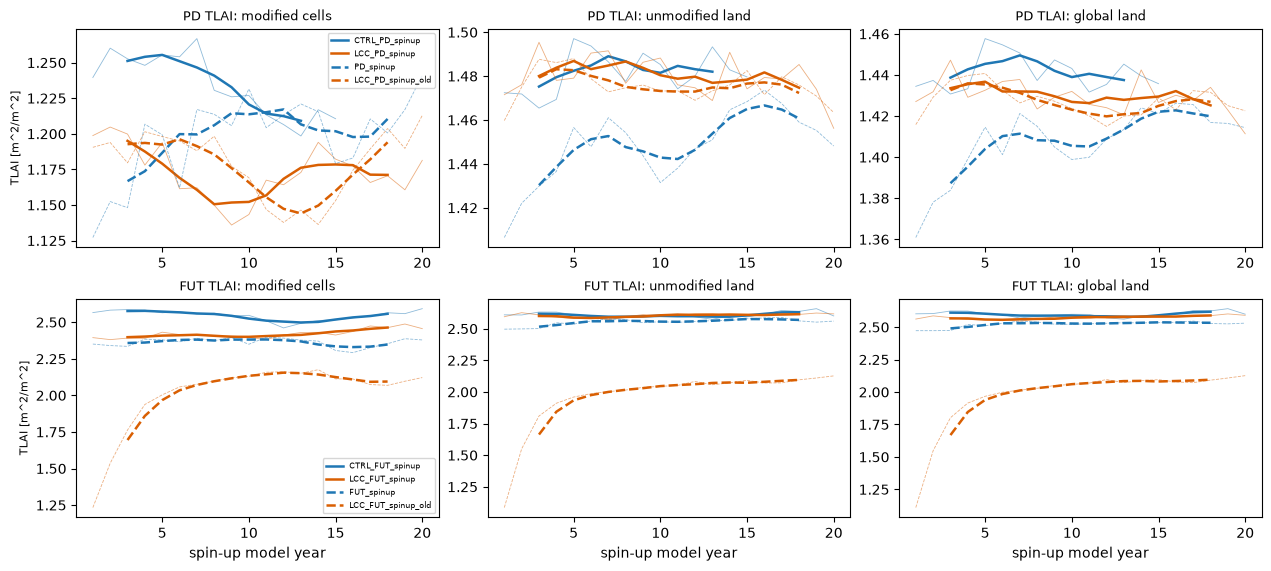

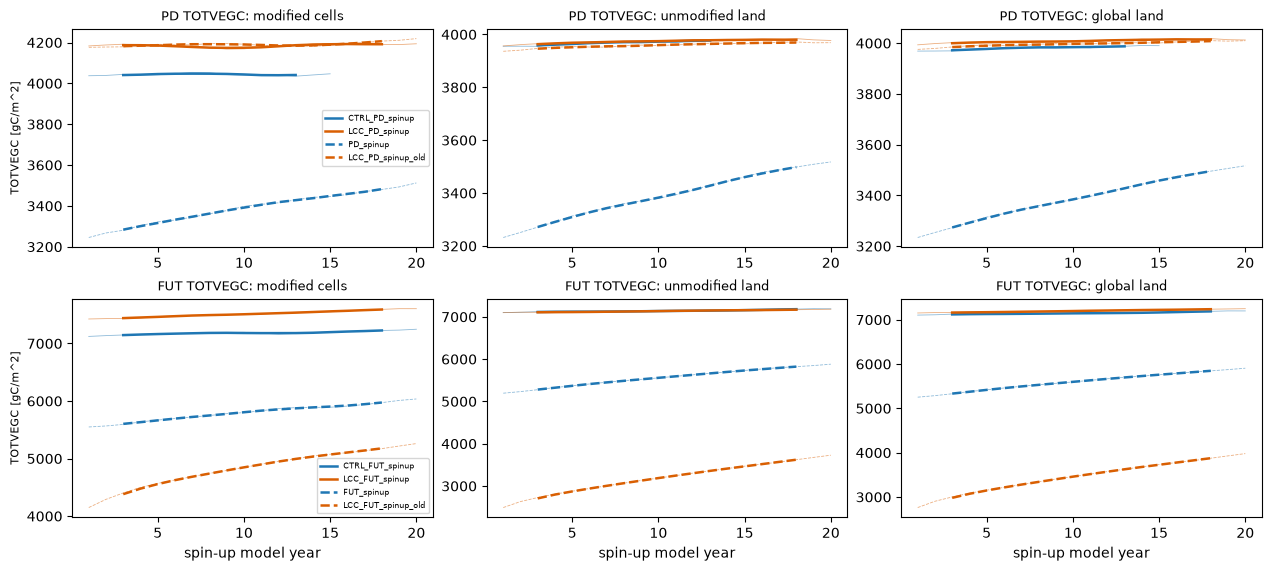

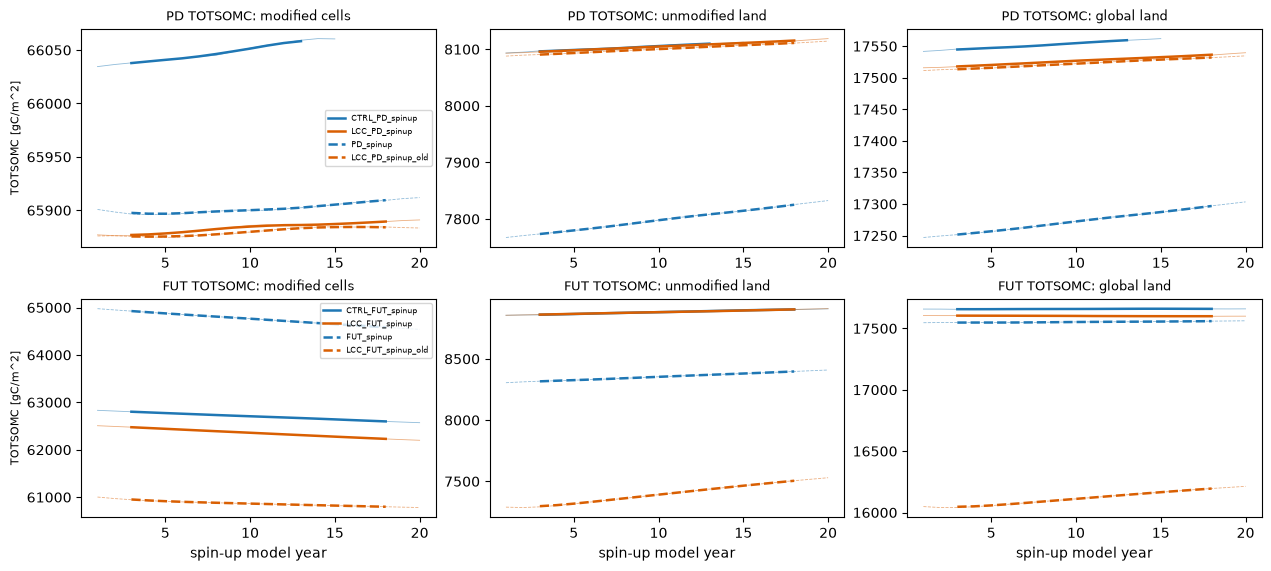

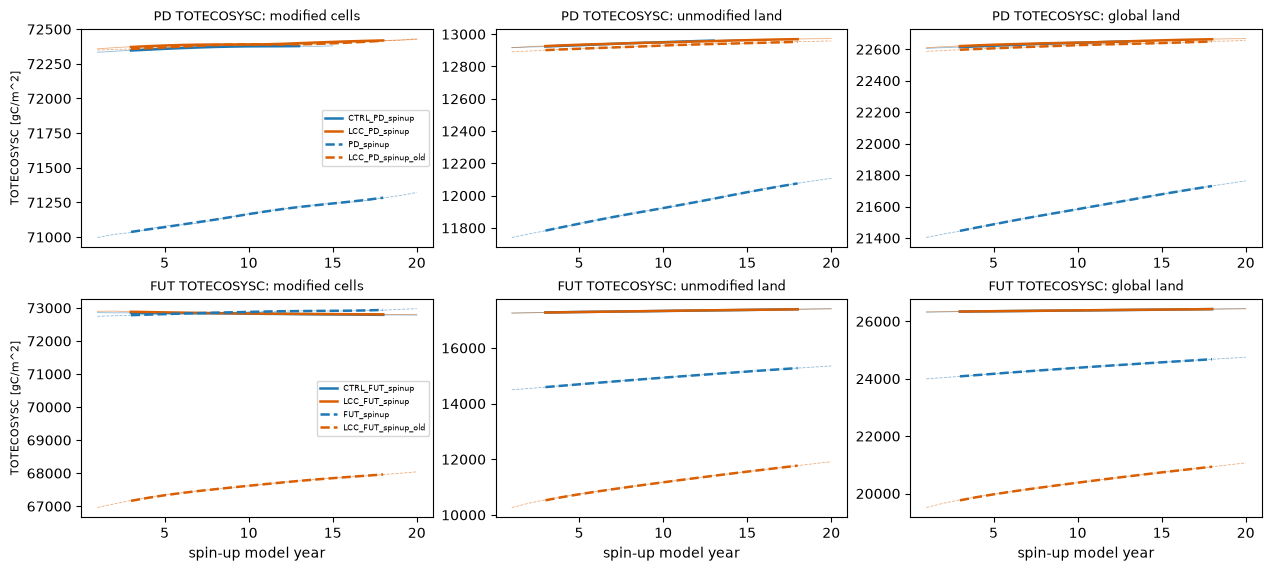

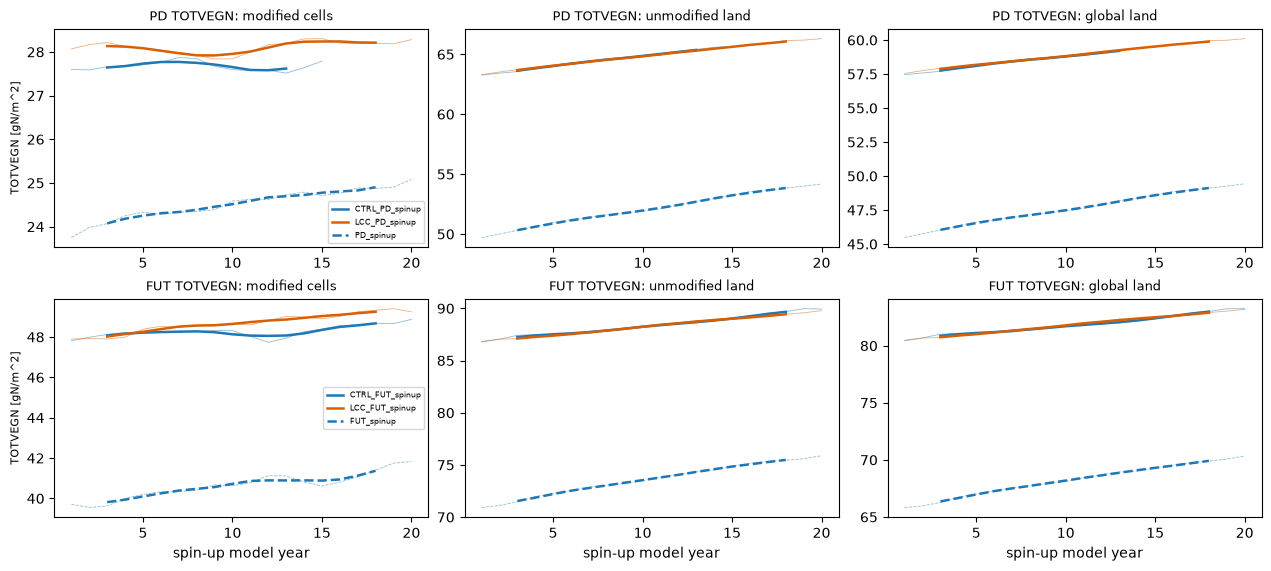

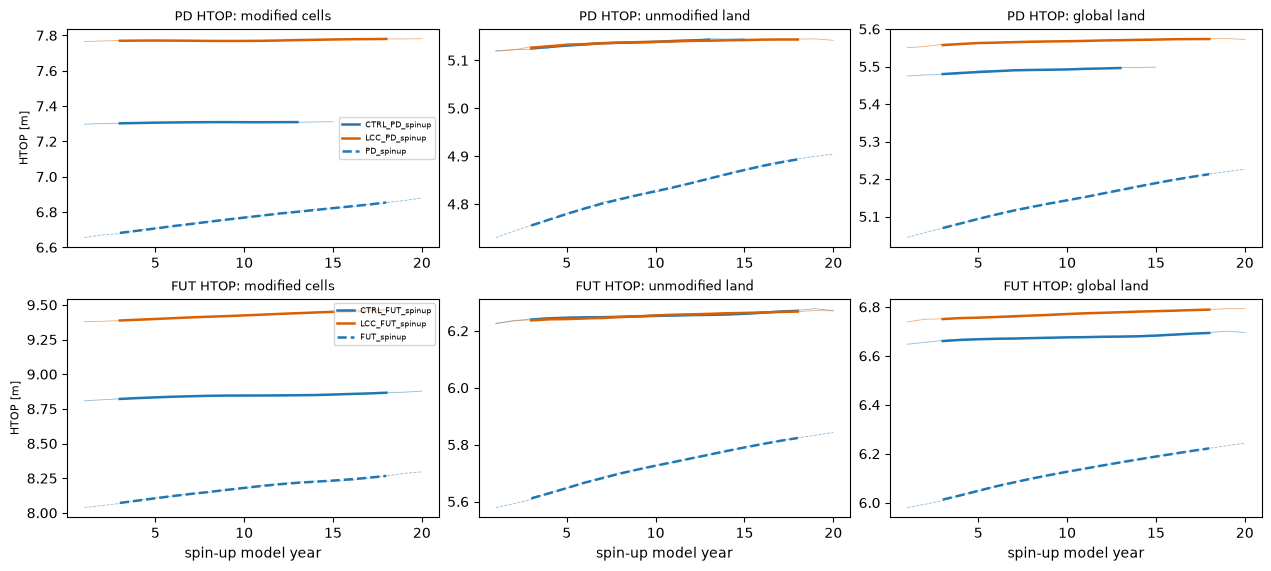

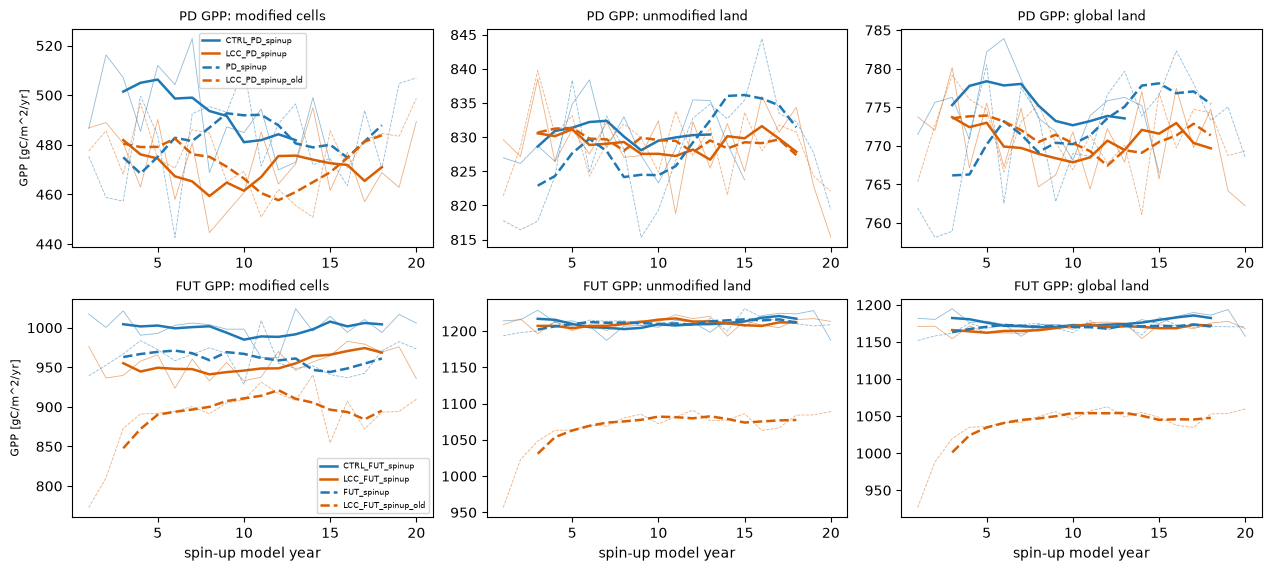

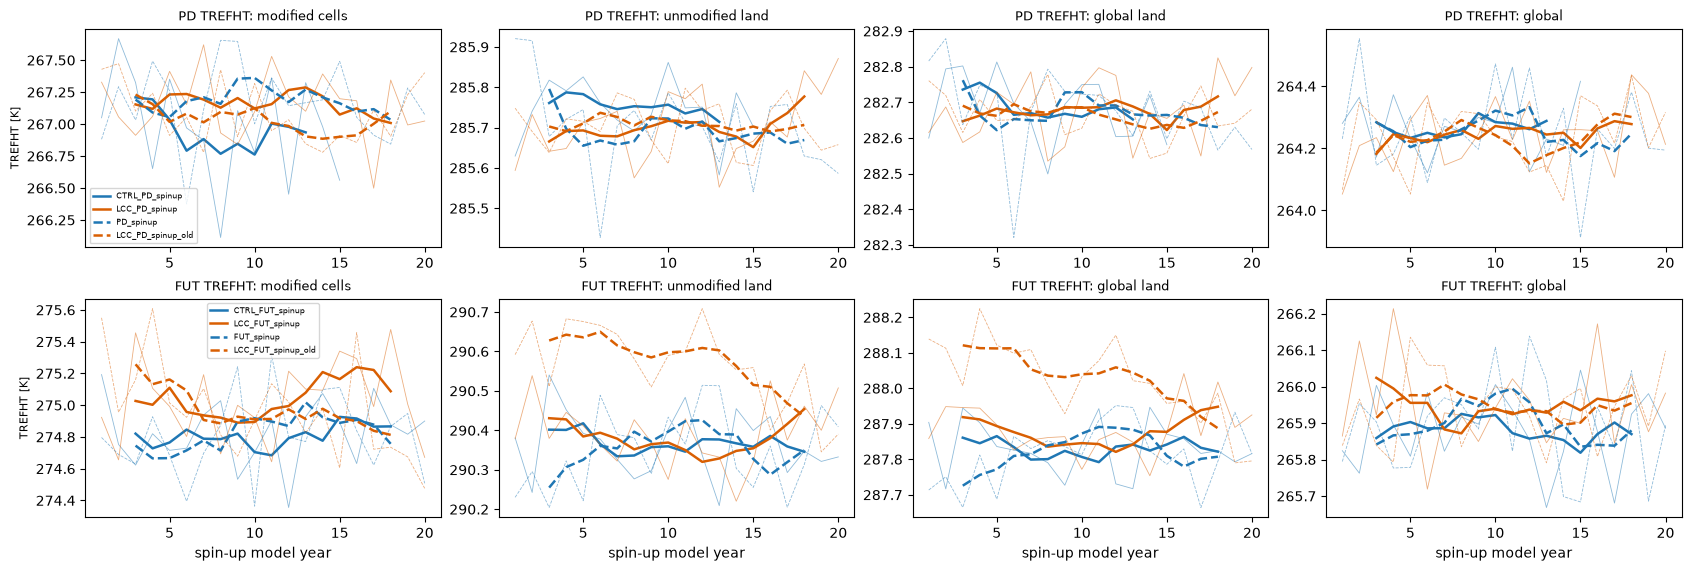

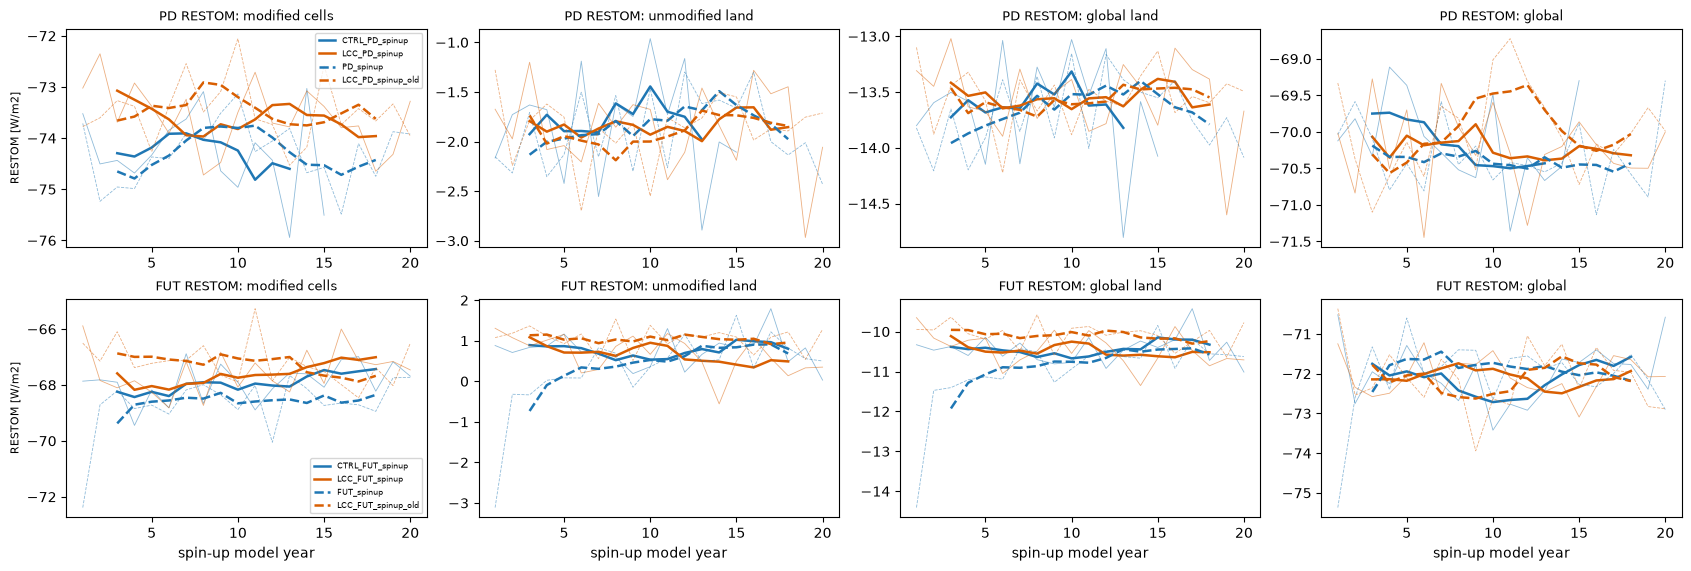

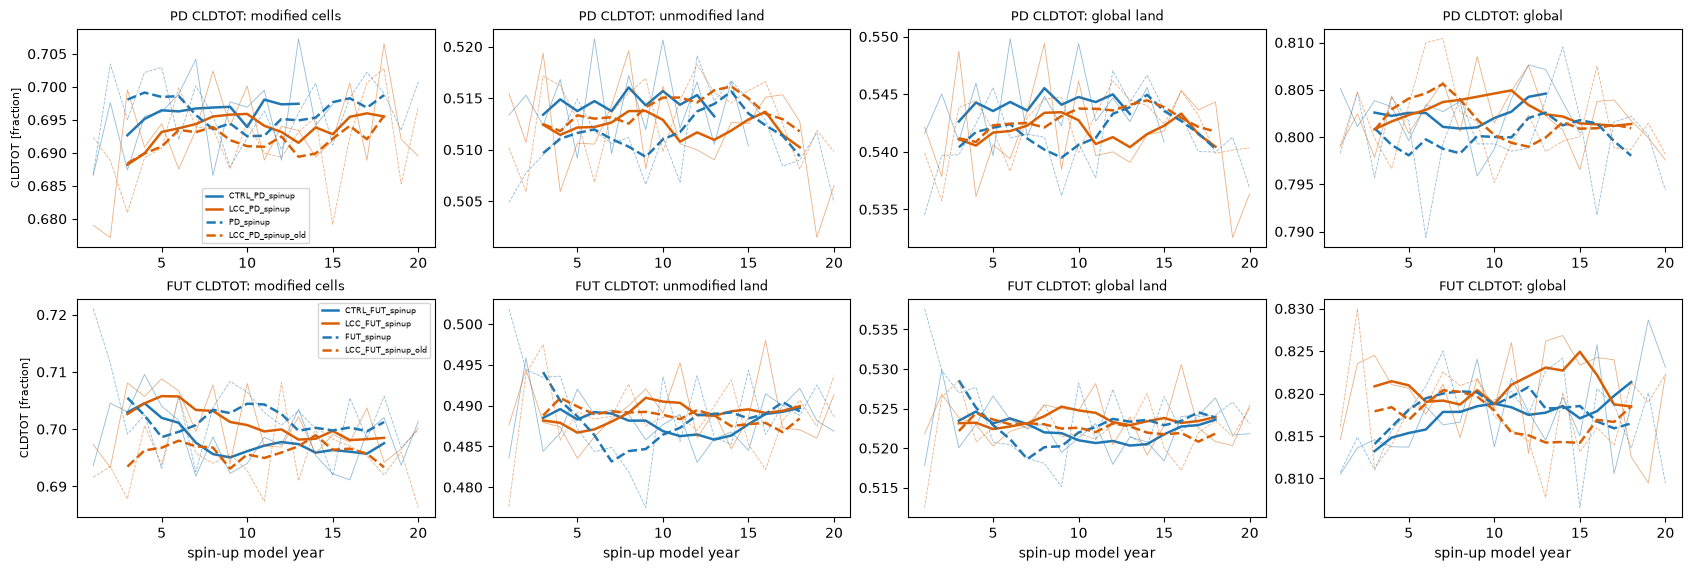

In [4]:
def series_figure(v):
    regs = regions_of(v)
    fig, axes = plt.subplots(2, len(regs), figsize=(4.2 * len(regs), 5.6), layout='constrained', squeeze=False)
    for i, period in enumerate(('PD', 'FUT')):
        for ax, region in zip(axes[i], regs):
            for run, s in RUNS[RUNS.period == period].iterrows():
                if (run, region, v) not in SERIES:
                    continue
                y = SERIES[run, region, v]
                ls = '-' if s.version == 'new' else '--'
                ax.plot(y.year, y, color=COLOR[run], lw=0.6, ls=ls, alpha=0.5)
                ax.plot(y.year, y.rolling(year=BLOCK, center=True).mean(), color=COLOR[run], lw=1.8, ls=ls, label=run)
            ax.set_title(f'{period} {v}: {region}', fontsize=9)
        axes[i, 0].set_ylabel(f'{v} [{units_of(v)}]', fontsize=8)
        axes[i, 0].legend(fontsize=6)
    for ax in axes[-1]:
        ax.set_xlabel('spin-up model year')
    fig.savefig(OUT / f'fig_series_{v}.png', dpi=150)
    plt.show()

for v in SHORT_TERM + SLOW + ATM:
    series_figure(v)

## 3. Drift at the end of each new spin-up

`ratio_ols` and `ratio_block` as defined at the top; `in_equilibrium` = both < 1. Short-term land state and the atmosphere are the criterion; slow pools are shown for information (also in % per decade).

In [5]:
def detrended_sd(y):
    x = y.year.values.astype(float)
    return float(np.std(y.values - np.polyval(np.polyfit(x, y.values, 1), x), ddof=2))

rows = []
for run in NEW:
    for v in SHORT_TERM + SLOW + ATM:
        for region in regions_of(v):
            if (run, region, v) not in SERIES:
                continue
            y = SERIES[run, region, v]
            last = y.isel(year=slice(-LAST, None))
            iav = detrended_sd(last)
            trend = LAST * np.polyfit(last.year.values.astype(float), last.values, 1)[0]
            block = float(y.isel(year=slice(-BLOCK, None)).mean() - y.isel(year=slice(-2 * BLOCK, -BLOCK)).mean())
            rows.append(dict(run=run, last_year=int(y.year[-1]), variable=v, region=region, units=units_of(v),
                             mean=float(last.mean()), iav_sd=iav, trend_per_decade=trend, block_diff=block,
                             ratio_ols=abs(trend) / iav, ratio_block=abs(block) / iav,
                             trend_pct_per_decade=100 * trend / float(last.mean())))
drift = pd.DataFrame(rows)
drift['in_equilibrium'] = (drift.ratio_ols < 1) & (drift.ratio_block < 1)
drift.to_csv(OUT / 'drift_last10yr.csv', index=False)

for group, vars_ in (('SHORT-TERM LAND', SHORT_TERM), ('ATMOSPHERE', ATM), ('SLOW POOLS (information)', SLOW)):
    sub = drift[drift.variable.isin(vars_)]
    print(f'{group}: ratio_ols / ratio_block  (< 1 = drift below noise)')
    t = sub.pivot_table(index=['variable', 'region'], columns='run', values=['ratio_ols', 'ratio_block'])
    display(t.reindex(columns=NEW, level=1).round(2))
    if group.startswith('SLOW'):
        print('SLOW POOLS: trend, % per decade')
        display(sub.pivot_table(index=['variable', 'region'], columns='run', values='trend_pct_per_decade')[NEW].round(2))
    print(f'  {int((~sub.in_equilibrium).sum())} of {len(sub)} with a ratio >= 1\n')
print('Last complete year per run:', drift.groupby('run').last_year.first().to_dict())

SHORT-TERM LAND: ratio_ols / ratio_block  (< 1 = drift below noise)


ratio_block                                \
run                       CTRL_PD_spinup LCC_PD_spinup CTRL_FUT_spinup   
variable  region                                                         
H2OSOI_1m global land               0.38          0.18            1.00   
          modified cells            0.56          0.83            1.34   
          unmodified land           0.20          0.36            0.86   
TLAI      global land               1.50          0.32            1.96   
          modified cells            2.57          0.47            3.54   
          unmodified land           0.70          0.23            1.52   
TSOI_1m   global land               0.14          0.10            0.15   
          modified cells            0.21          2.30            0.88   
          unmodified land           0.31          0.78            0.62   
TWS       global land               0.17          0.37            1.47   
          modified cells            0.73          1.36            1.82   
          unmodified land           0.29          0.64            1.35   

                                              ratio_ols                \
run                       LCC_FUT_spinup CTRL_PD_spinup LCC_PD_spinup   
variable  region                                                        
H2OSOI_1m global land               1.28           0.69          1.20   
          modified cells            0.33           1.39          1.06   
          unmodified land           1.20           1.09          1.42   
TLAI      global land               1.57           2.55          0.80   
          modified cells            2.92           4.78          0.01   
          unmodified land           0.60           1.04          0.84   
TSOI_1m   global land               2.51           0.66          0.10   
          modified cells            0.51           0.32          4.23   
          unmodified land           2.25           0.78          1.16   
TWS       global land               2.01           1.09          1.58   
          modified cells            0.33           2.32          1.92   
          unmodified land           2.42           1.49          1.92   

                                                          
run                       CTRL_FUT_spinup LCC_FUT_spinup  
variable  region                                          
H2OSOI_1m global land                0.98           2.55  
          modified cells             2.71           0.15  
          unmodified land            0.64           2.17  
TLAI      global land                2.95           3.00  
          modified cells             6.86           5.36  
          unmodified land            2.07           1.25  
TSOI_1m   global land                0.28           3.64  
          modified cells             2.04           0.66  
          unmodified land            1.34           3.32  
TWS       global land                1.68           3.79  
          modified cells             2.88           0.25  
          unmodified land            1.47           4.28

  34 of 48 with a ratio >= 1

ATMOSPHERE: ratio_ols / ratio_block  (< 1 = drift below noise)


ratio_block                                \
run                      CTRL_PD_spinup LCC_PD_spinup CTRL_FUT_spinup   
variable region                                                         
CLDTOT   global                    0.99          0.35            0.65   
         global land               0.72          0.01            1.30   
         modified cells            0.09          0.67            0.03   
         unmodified land           0.65          0.17            1.37   
RESTOM   global                    0.38          0.18            1.34   
         global land               0.71          0.04            0.22   
         modified cells            0.61          1.22            1.17   
         unmodified land           0.58          0.26            0.01   
TREFHT   global                    0.39          0.31            0.04   
         global land               0.06          0.27            0.25   
         modified cells            0.41          1.07            0.16   
         unmodified land           0.52          0.92            0.37   

                                             ratio_ols                \
run                      LCC_FUT_spinup CTRL_PD_spinup LCC_PD_spinup   
variable region                                                        
CLDTOT   global                    0.72           0.61          2.19   
         global land               0.26           1.20          0.69   
         modified cells            0.10           0.04          0.65   
         unmodified land           0.26           1.03          0.95   
RESTOM   global                    1.23           0.36          0.96   
         global land               0.19           1.30          0.48   
         modified cells            0.90           1.54          1.91   
         unmodified land           0.03           0.95          0.12   
TREFHT   global                    0.45           0.96          0.64   
         global land               1.35           0.19          0.39   
         modified cells            0.03           0.25          1.76   
         unmodified land           1.44           0.53          1.46   

                                                         
run                      CTRL_FUT_spinup LCC_FUT_spinup  
variable region                                          
CLDTOT   global                     1.01           1.28  
         global land                1.32           0.36  
         modified cells             0.05           0.17  
         unmodified land            1.39           0.39  
RESTOM   global                     3.02           1.32  
         global land                0.24           0.90  
         modified cells             1.95           0.76  
         unmodified land            0.64           1.14  
TREFHT   global                     0.54           0.05  
         global land                0.43           1.60  
         modified cells             0.76           0.07  
         unmodified land            0.88           1.68

  18 of 48 with a ratio >= 1

SLOW POOLS (information): ratio_ols / ratio_block  (< 1 = drift below noise)


ratio_block                                \
run                        CTRL_PD_spinup LCC_PD_spinup CTRL_FUT_spinup   
variable   region                                                         
GPP        global land               0.38          0.04            0.74   
           modified cells            0.72          0.34            0.67   
           unmodified land           0.06          0.16            0.55   
HTOP       global land               5.01          2.48            4.36   
           modified cells            0.22          4.36            5.40   
           unmodified land           4.88          1.84            3.73   
TOTECOSYSC global land              15.98          8.91           14.98   
           modified cells            2.24          8.59            4.93   
           unmodified land          14.89          8.41           16.69   
TOTSOMC    global land              14.92         14.88            0.43   
           modified cells           10.23          5.45           57.95   
           unmodified land          14.17         15.73           13.97   
TOTVEGC    global land               2.33          1.01            6.71   
           modified cells            1.30          1.08            6.01   
           unmodified land           3.12          0.81            6.08   
TOTVEGN    global land              14.43         14.69           10.24   
           modified cells            1.12          0.24            4.42   
           unmodified land          17.17         17.14            9.47   

                                               ratio_ols                \
run                        LCC_FUT_spinup CTRL_PD_spinup LCC_PD_spinup   
variable   region                                                        
GPP        global land               0.13           2.05          0.54   
           modified cells            0.78           1.75          0.39   
           unmodified land           0.17           1.02          0.38   
HTOP       global land               9.42          10.48          4.82   
           modified cells           11.49           1.26          9.19   
           unmodified land           7.29          10.04          3.41   
TOTECOSYSC global land              13.29          33.09         18.26   
           modified cells            5.75           4.69         17.68   
           unmodified land          16.17          30.82         17.20   
TOTSOMC    global land               1.23          28.80         29.51   
           modified cells           57.94          19.63         10.19   
           unmodified land          33.49          27.38         31.36   
TOTVEGC    global land               9.96           5.41          2.23   
           modified cells           10.93           2.21          3.03   
           unmodified land           6.86           6.86          1.55   
TOTVEGN    global land              12.75          29.37         29.72   
           modified cells            3.42           1.74          1.69   
           unmodified land          12.61          34.68         34.25   

                                                           
run                        CTRL_FUT_spinup LCC_FUT_spinup  
variable   region                                          
GPP        global land                0.71           0.22  
           modified cells             2.08           0.78  
           unmodified land            0.13           0.51  
HTOP       global land                8.06          19.42  
           modified cells            10.78          23.69  
           unmodified land            6.77          15.03  
TOTECOSYSC global land               29.93          27.25  
           modified cells             9.78          10.47  
           unmodified land           33.32          32.84  
TOTSOMC    global land                0.15           2.74  
           modified cells           114.72         115.94  
           unmodified land           28.49          66.62  

SLOW POOLS: trend, % per decade


run                         CTRL_PD_spinup  LCC_PD_spinup  CTRL_FUT_spinup  \
variable   region                                                            
GPP        global land               -1.17          -0.41             0.67   
           modified cells            -5.84          -1.12             3.93   
           unmodified land           -0.63          -0.33             0.15   
HTOP       global land                0.20           0.11             0.41   
           modified cells             0.02           0.17             0.41   
           unmodified land            0.25           0.09             0.41   
TOTECOSYSC global land                0.13           0.12             0.24   
           modified cells             0.02           0.06            -0.06   
           unmodified land            0.26           0.19             0.49   
TOTSOMC    global land                0.09           0.07            -0.00   
           modified cells             0.03           0.01            -0.22   
           unmodified land            0.18           0.17             0.30   
TOTVEGC    global land                0.24           0.13             0.93   
           modified cells            -0.26           0.32             1.21   
           unmodified land            0.34           0.09             0.88   
TOTVEGN    global land                2.24           2.16             2.12   
           modified cells            -0.73           0.49             2.37   
           unmodified land            2.49           2.30             2.10   

run                         LCC_FUT_spinup  
variable   region                           
GPP        global land               -0.14  
           modified cells             1.43  
           unmodified land           -0.38  
HTOP       global land                0.33  
           modified cells             0.52  
           unmodified land            0.27  
TOTECOSYSC global land                0.20  
           modified cells            -0.04  
           unmodified land            0.39  
TOTSOMC    global land               -0.01  
           modified cells            -0.26  
           unmodified land            0.33  
TOTVEGC    global land                0.70  
           modified cells             1.42  
           unmodified land            0.55  
TOTVEGN    global land                1.59  
           modified cells             1.53  
           unmodified land            1.60

  63 of 72 with a ratio >= 1

Last complete year per run: {'CTRL_FUT_spinup': 20, 'CTRL_PD_spinup': 15, 'LCC_FUT_spinup': 20, 'LCC_PD_spinup': 20}


## 4. Members: LCC − CTRL, last 10 common years

Δ of the 10-yr means; `delta_in_iav` uses CTRL's detrended IAV. New pairs (same spin-up history) against old pairs (different history). Expected for the new chain: in unmodified land, slow pools differ by much less than in the old pairs.

In [6]:
rows = []
for pair, (c, l) in PAIRS.items():
    for v in SHORT_TERM + SLOW + ATM:
        for region in regions_of(v):
            if (c, region, v) not in SERIES or (l, region, v) not in SERIES:
                continue
            yc, yl = SERIES[c, region, v], SERIES[l, region, v]
            common = np.intersect1d(yc.year, yl.year)[-LAST:]
            yc, yl = yc.sel(year=common), yl.sel(year=common)
            sd = detrended_sd(yc)
            delta = float(yl.mean() - yc.mean())
            rows.append(dict(pair=pair, years=f'{common[0]}-{common[-1]}', variable=v, region=region, units=units_of(v),
                             CTRL=float(yc.mean()), LCC=float(yl.mean()), delta=delta,
                             delta_pct=100 * delta / float(yc.mean()), delta_in_iav=delta / sd if sd > 0 else np.nan))
members = pd.DataFrame(rows)
members.to_csv(OUT / 'LCC_minus_CTRL_last10yr.csv', index=False)
ORDER = [p for p in PAIRS if p in set(members.pair)]
print('Years used:', members.groupby('pair').years.first().to_dict())
for region in ('unmodified land', 'modified cells', 'global land'):
    print(f'{region}: Δ in % (left) and in CTRL IAV units (right)')
    sub = members[members.region == region]
    display(pd.concat({'delta_pct': sub.pivot_table(index='variable', columns='pair', values='delta_pct')[ORDER],
                       'delta_in_iav': sub.pivot_table(index='variable', columns='pair', values='delta_in_iav')[ORDER]},
                      axis=1).round(2))

Years used: {'FUT new': '11-20', 'FUT old': '11-20', 'PD new': '6-15', 'PD old': '11-20'}
unmodified land: Δ in % (left) and in CTRL IAV units (right)


delta_pct                        delta_in_iav                  \
pair          PD new FUT new PD old FUT old       PD new FUT new  PD old   
variable                                                                   
CLDTOT         -0.44    0.32   0.37   -0.11        -0.53    0.55    0.45   
GPP            -0.27   -0.06  -0.42  -10.94        -0.44   -0.05   -0.53   
H2OSOI_1m      -0.05   -0.27  -0.50    1.34        -0.13   -0.46   -1.23   
HTOP           -0.01    0.01    NaN     NaN        -0.59    0.16     NaN   
RESTOM          5.50  -37.59  -3.54   31.42        -0.16   -0.57    0.17   
TLAI           -0.17   -0.03   1.12  -18.83        -0.38   -0.04    1.44   
TOTECOSYSC     -0.01   -0.00   7.63  -23.61        -1.27   -0.17  266.51   
TOTSOMC        -0.01   -0.01   3.72  -10.89        -1.57   -0.61  472.36   
TOTVEGC         0.04   -0.06  14.54  -39.23         0.84   -0.81   89.74   
TOTVEGN        -0.06   -0.10    NaN     NaN        -0.85   -0.88     NaN   
TREFHT         -0.01    0.01   0.01    0.05        -0.56    0.36    0.48   
TSOI_1m        -0.01    0.00   0.00    0.11        -0.50    0.17    0.25   
TWS             0.00   -0.01    NaN     NaN         0.04   -0.20     NaN   

                     
pair        FUT old  
variable             
CLDTOT        -0.15  
GPP          -14.84  
H2OSOI_1m      3.88  
HTOP            NaN  
RESTOM         0.55  
TLAI         -34.06  
TOTECOSYSC  -869.98  
TOTSOMC    -1512.32  
TOTVEGC     -418.17  
TOTVEGN         NaN  
TREFHT         1.36  
TSOI_1m        3.99  
TWS             NaN

modified cells: Δ in % (left) and in CTRL IAV units (right)


delta_pct                        delta_in_iav                  \
pair          PD new FUT new PD old FUT old       PD new FUT new  PD old   
variable                                                                   
CLDTOT         -0.52    0.12  -0.62   -0.76        -0.55    0.19   -1.09   
GPP            -4.15   -3.63  -2.44   -6.08        -1.24   -1.92   -0.78   
H2OSOI_1m      -0.79    0.07   0.06   -0.60        -1.91    0.22    0.11   
HTOP            6.32    6.71    NaN     NaN       340.50  174.81     NaN   
RESTOM         -0.90   -0.65  -0.91   -1.61         0.72    0.82    1.22   
TLAI           -5.03   -3.53  -3.27   -9.97        -5.00   -5.33   -2.12   
TOTECOSYSC      0.03    0.02   1.62   -6.94         7.10    2.79  243.44   
TOTSOMC        -0.25   -0.58  -0.03   -5.91      -143.23 -298.90  -87.55   
TOTVEGC         3.38    4.99  21.42  -14.14        28.22   47.55  186.62   
TOTVEGN         1.35    1.41    NaN     NaN         3.22    5.01     NaN   
TREFHT          0.13    0.09  -0.06   -0.01         0.86    1.05   -0.80   
TSOI_1m         0.11    0.08  -0.02    0.07         2.18    1.96   -0.30   
TWS            -0.16   -0.04    NaN     NaN        -1.01   -0.39     NaN   

                     
pair        FUT old  
variable             
CLDTOT        -1.20  
GPP           -2.43  
H2OSOI_1m     -1.15  
HTOP            NaN  
RESTOM         1.45  
TLAI          -6.12  
TOTECOSYSC  -392.39  
TOTSOMC    -2485.49  
TOTVEGC      -50.05  
TOTVEGN         NaN  
TREFHT        -0.12  
TSOI_1m        1.61  
TWS             NaN

global land: Δ in % (left) and in CTRL IAV units (right)


delta_pct                        delta_in_iav                  \
pair          PD new FUT new PD old FUT old       PD new FUT new  PD old   
variable                                                                   
CLDTOT         -0.46    0.28   0.16   -0.25        -0.81    0.58    0.26   
GPP            -0.67   -0.55  -0.63  -10.29        -1.17   -0.58   -1.04   
H2OSOI_1m      -0.23   -0.20  -0.37    0.92        -0.72   -0.41   -0.91   
HTOP            1.36    1.46    NaN     NaN        72.09   28.71     NaN   
RESTOM         -0.19    1.73  -1.20   -3.66         0.05   -0.37    0.58   
TLAI           -0.85   -0.59   0.51  -17.48        -2.01   -0.77    0.94   
TOTECOSYSC      0.01    0.01   4.41  -15.55         2.19    0.73  402.62   
TOTSOMC        -0.16   -0.34   1.39   -7.90       -50.86  -64.35  476.25   
TOTVEGC         0.59    0.76  15.66  -35.03        13.38   10.28  126.87   
TOTVEGN         0.05    0.04    NaN     NaN         0.62    0.39     NaN   
TREFHT          0.01    0.02   0.00    0.04         0.26    0.79    0.13   
TSOI_1m         0.01    0.02   0.00    0.11         0.46    0.86    0.05   
TWS            -0.01   -0.02    NaN     NaN        -0.14   -0.23     NaN   

                     
pair        FUT old  
variable             
CLDTOT        -0.52  
GPP          -17.37  
H2OSOI_1m      3.40  
HTOP            NaN  
RESTOM         1.22  
TLAI         -66.01  
TOTECOSYSC -1769.23  
TOTSOMC    -2109.42  
TOTVEGC     -684.83  
TOTVEGN         NaN  
TREFHT         1.40  
TSOI_1m        4.54  
TWS             NaN

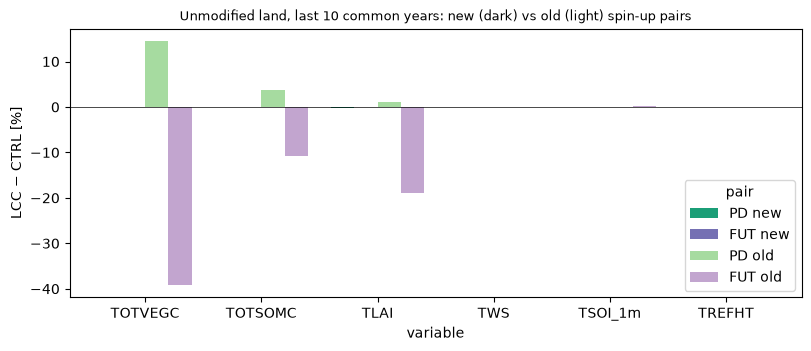

In [7]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
SHOW = ['TOTVEGC', 'TOTSOMC', 'TLAI', 'TWS', 'TSOI_1m', 'TREFHT']
sub = members[(members.region == 'unmodified land') & members.variable.isin(SHOW)]
piv = sub.pivot_table(index='variable', columns='pair', values='delta_pct').reindex(index=SHOW)[ORDER]
fig, ax = plt.subplots(figsize=(8, 3.4), layout='constrained')
piv.plot.bar(ax=ax, color=['#5D9A92', '#2C3990', '#9A4A84', '#BC423E'][:len(ORDER)], width=0.8)
ax.axhline(0, color='k', lw=0.5)
ax.set_ylabel('LCC − CTRL [%]')
ax.set_title('Unmodified land, last 10 common years: new (dark) vs old (light) spin-up pairs', fontsize=9)
ax.tick_params(axis='x', rotation=0)
fig.savefig(OUT / 'fig_members_unmodified_land.png', dpi=150)
plt.show()

## Summary (run 2026-10-28 16:0x; outputs saved in this notebook and in `check_coupled_spinup_equilibrium_after_co2_fix_outputs/`)

👉 **The spin-up mismatch between CTRL and LCC is gone. The new spin-ups are not perfectly flat, but CTRL and LCC drift together and their differences stay within noise outside the modified cells.** `CTRL_PD_spinup` had only years 1–15 at this run: **rerun after it ends (~29 Oct 05:00)**.

**Members, unmodified land, last 10 common years (a, §4, `LCC_minus_CTRL_last10yr.csv`):**
| LCC − CTRL | PD new (yrs 6–15) | FUT new (11–20) | PD old (11–20) | FUT old (11–20) |
|---|---|---|---|---|
| TOTVEGC | +0.04 % (0.8 IAV) | −0.06 % (−0.8 IAV) | **+14.5 %** (90 IAV) | **−39 %** (−418 IAV) |
| TOTSOMC | −0.01 % | −0.01 % | +3.7 % | −10.9 % |
| TLAI | −0.17 % | −0.03 % | +1.1 % | **−19 %** |
| TSOI at 1.06 m | −0.01 % (−0.5 IAV) | 0.00 % (0.2 IAV) | 0.00 % | +0.11 % (4.0 IAV) |
| TREFHT | −0.6 IAV | +0.4 IAV | +0.5 IAV | +1.4 IAV |

Every new-pair |Δ| in unmodified land is ≤ 1.6 IAV and ≤ 0.5 % (RESTOM % is meaningless, near-zero mean). The old pairs differ by tens to hundreds of IAV in the carbon pools. In the modified cells the new pairs show the expected land-cover signal (HTOP +6–7 %, TOTVEGC +3–5 %, TLAI −4…−5 %).

**Why the old pairs differed (a, TOTVEGC figure):** the old CTRL spin-ups (`PD_spinup`, `FUT_spinup`) started from the original initial files and were still building vegetation carbon fast (PD unmodified land 3230 → 3520 gC/m² over 20 yr, ≈ +4 %/decade), while LCC started from the 100-yr land-only state. The new CTRL and LCC both start from land-only states and are almost flat (TOTVEGC 0.1–1.4 %/decade).

**Drift at the end of the new spin-ups (a, §3, `drift_last10yr.csv`):**
- **Atmosphere:** 18 of 48 ratios ≥ 1, mostly around 1–1.7, global RESTOM in CTRL_FUT_spinup 3.0 (trend 1.6 W m⁻²/decade with IAV 0.53). No systematic sign across runs.
- **Short-term land:** 34 of 48 ratios ≥ 1. The series wander on multi-year time scales rather than trend: TWS moves by ±10 mm around ≈ 8450–8500 mm (≈ 0.1 %; unmodified-land trends −14…+9 mm/decade); TSOI at 1.06 m trends by −0.07…+0.16 K/decade in unmodified land (largest in LCC_FUT_spinup). The regional means are so smooth that one IAV is tiny (TWS 4–6 mm, TSOI 0.05 K), so the ratio flags small changes (b). TLAI trends by −1.1 to +2.3 %/decade (global land), up to ±4.8 %/decade in the modified cells of the CTRL runs.
- **Slow pools (information):** still changing, by 0.1–0.9 %/decade (TOTVEGC, TOTECOSYSC, TOTSOMC) and ≈ 2 %/decade (TOTVEGN), in CTRL and LCC alike.

**Interpretation (b):** what matters for LCC − CTRL in the nudged runs is that both members start from comparable states and drift alike. That holds now and did not before. A residual drift that is common to CTRL and LCC largely cancels in the contrast; it does not cancel in CTRL_FUT − CTRL_PD.

**Limits:** the members test uses one 10-yr window per pair, with no autocorrelation correction. Regional means can hide opposing cell-level changes. Only five CAM fields are in the spin-up output (TREFHT, TS, FSNT, FLNT, CLDTOT), so aerosol and cloud-microphysics equilibrium is not tested here. Old FUT spin-ups have no TWS, HTOP or TOTVEGN in LCC.
